In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from src.data.data_acquire import load_df
except ModuleNotFoundError:
    from data_acquire import load_df

sns.set_theme(style="whitegrid")
df = load_df()
print(df.shape)
print(df.head())

(1602, 22)
   listing_id property_type                                            title  \
0   112882085          Room            Room in Arriaza, 6, Argüelles, Madrid   
1   109593439          Room  Room in Calle de Calatrava, 25, Palacio, Madrid   
2   112882222          Room            Room in Arriaza, 6, Argüelles, Madrid   
3   112806578          Room                 Room in Segovia, Palacio, Madrid   
4   112874349          Room                  Room in Goya, 133, Goya, Madrid   

                                                url              street  \
0  https://www.idealista.com/en/inmueble/112882085/             Arriaza   
1  https://www.idealista.com/en/inmueble/109593439/  Calle de Calatrava   
2  https://www.idealista.com/en/inmueble/112882222/             Arriaza   
3  https://www.idealista.com/en/inmueble/112806578/             Segovia   
4  https://www.idealista.com/en/inmueble/112874349/                Goya   

   house_number neighborhood    city  price_eur  extra_mo

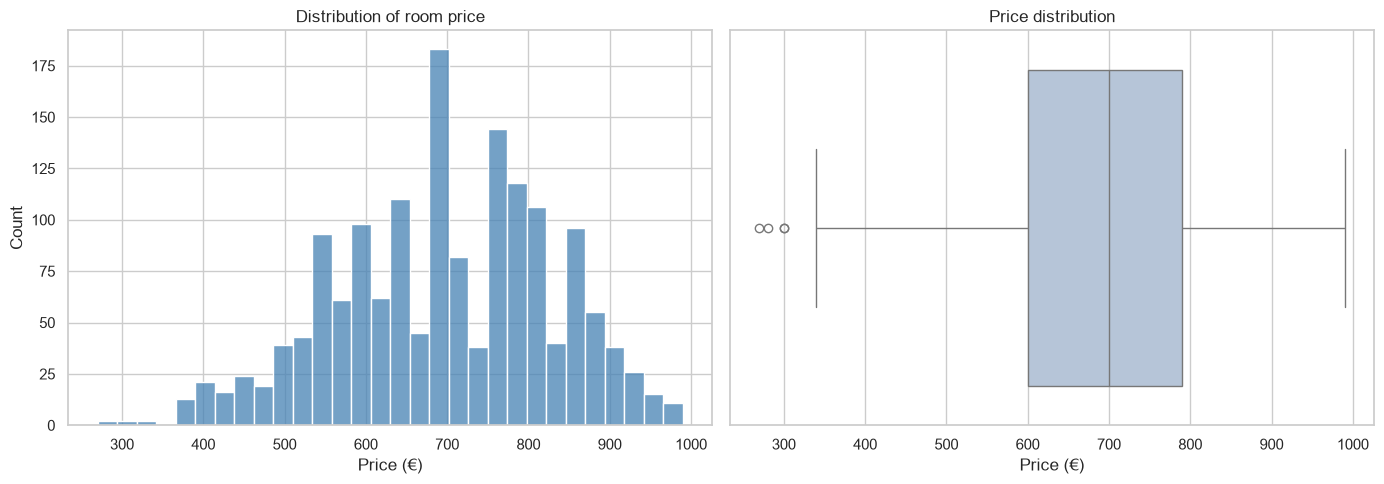

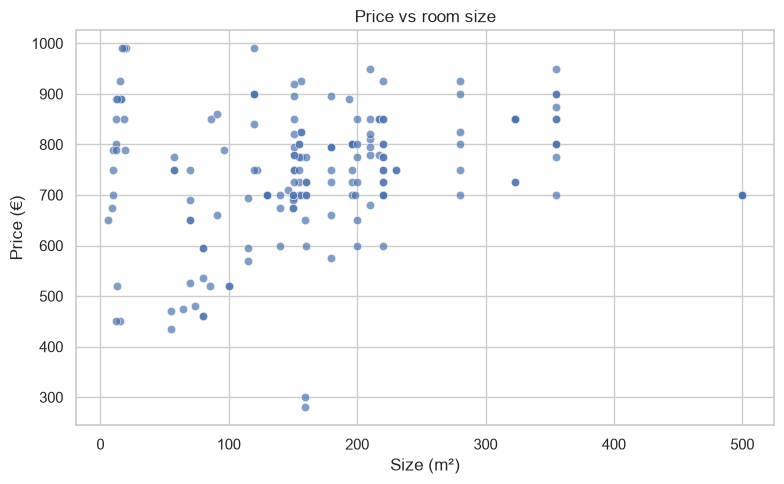

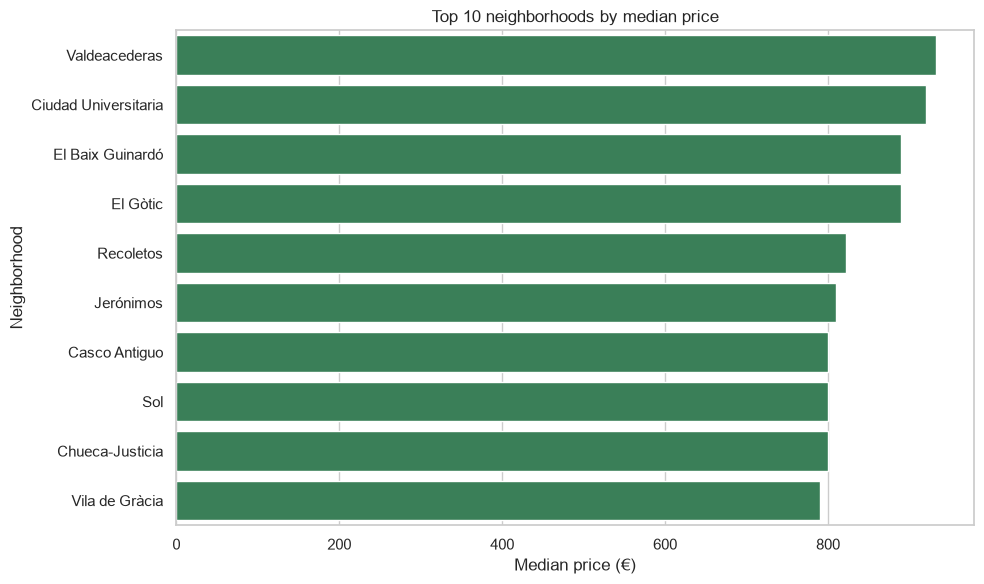

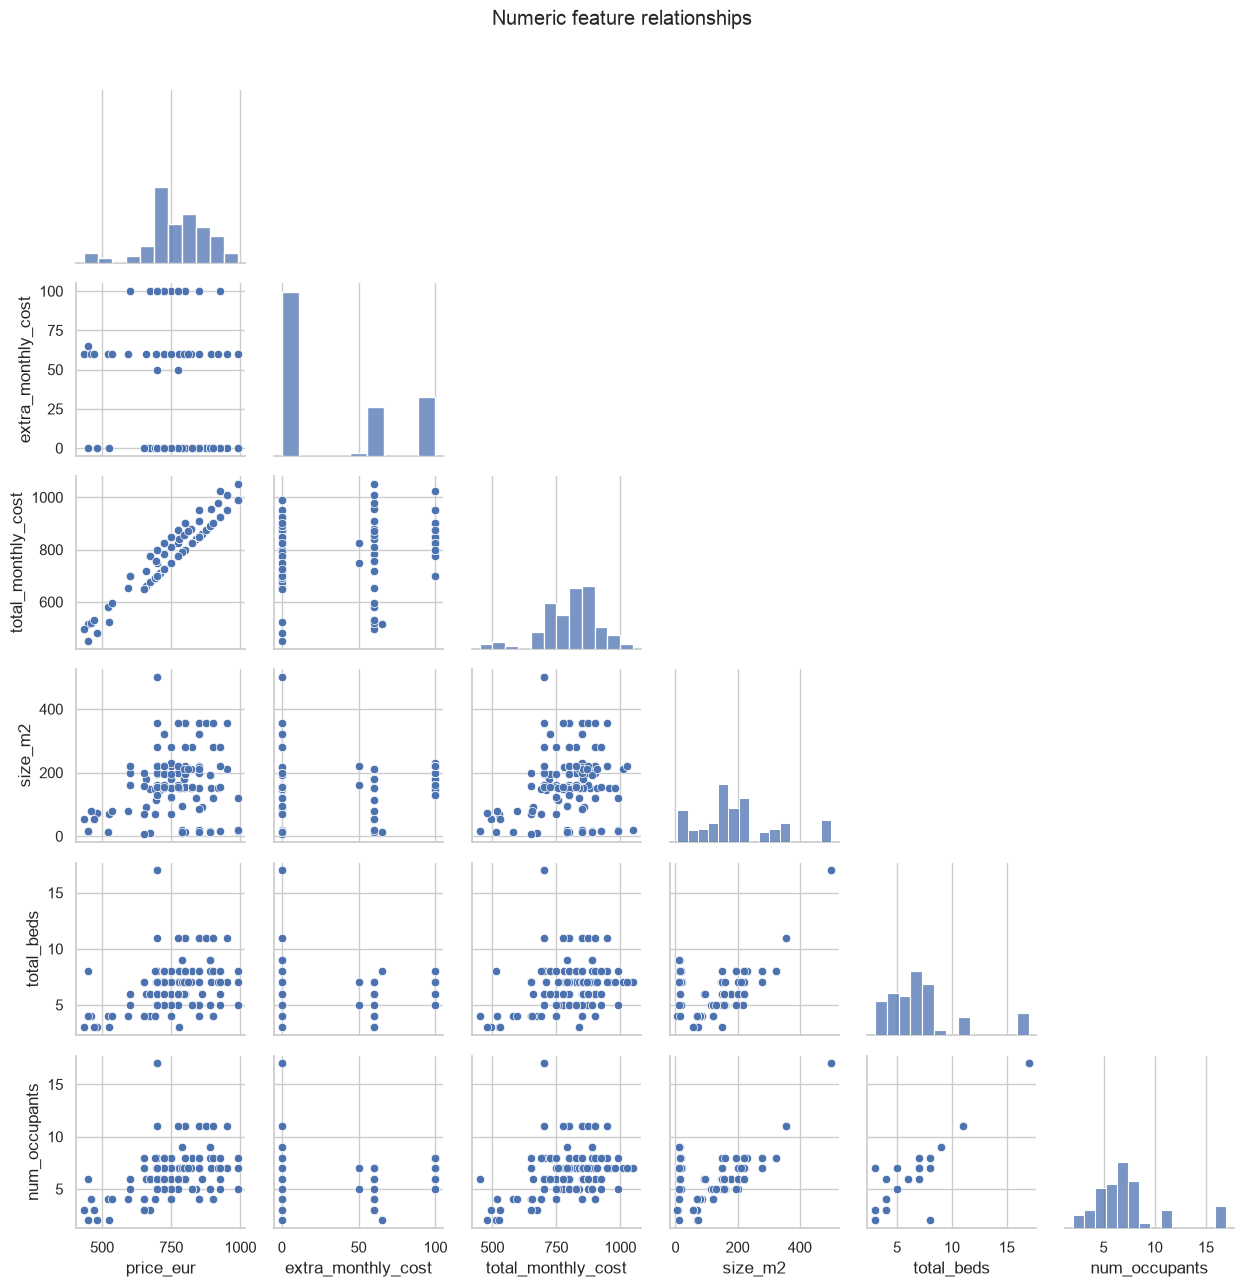

In [3]:
# Price distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['price_eur'], bins=30, ax=axes[0], color='steelblue')
axes[0].set_title('Distribution of room price')
axes[0].set_xlabel('Price (€)')

sns.boxplot(x=df['price_eur'], ax=axes[1], color='lightsteelblue')
axes[1].set_title('Price distribution')
axes[1].set_xlabel('Price (€)')

plt.tight_layout()

# Price vs size
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df.dropna(subset=['size_m2', 'price_eur']), x='size_m2', y='price_eur', alpha=0.7)
plt.title('Price vs room size')
plt.xlabel('Size (m²)')
plt.ylabel('Price (€)')
plt.tight_layout()

# Neighborhood median pricing
neighborhood_prices = (
    df.groupby('neighborhood', dropna=False)['price_eur']
    .median()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))
sns.barplot(x=neighborhood_prices.values, y=neighborhood_prices.index, color='seagreen')
plt.title('Top 10 neighborhoods by median price')
plt.xlabel('Median price (€)')
plt.ylabel('Neighborhood')
plt.tight_layout()

# Numeric summary pairwise relationships
numeric_cols = ['price_eur', 'extra_monthly_cost', 'total_monthly_cost', 'size_m2', 'total_beds', 'num_occupants']
plot_df = df[numeric_cols].dropna().sample(min(len(df[numeric_cols].dropna()), 500), random_state=42)

sns.pairplot(plot_df, diag_kind='hist', corner=True, height=2.1)
plt.suptitle('Numeric feature relationships', y=1.02)
plt.tight_layout()